In [1]:
from pathlib import Path
import sys
PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

from src.data.labels import load_labels
import matplotlib.pyplot as plt
from src.analysis.patient_analysis import (
    analyze_bounding_boxes,
    analyze_images_per_patient,
    check_duplicate_patients,
)

NEW LABELS.PY LOADED


In [2]:
csv_path = Path(
    "../data/raw/rsna-pneumonia-detection-challenge/stage_2_train_labels.csv"
)

image_dir = Path(
    "../data/raw/rsna-pneumonia-detection-challenge/stage_2_train_images"
)

labels, _ = load_labels(csv_path)

In [3]:
image_df = analyze_images_per_patient(image_dir)
image_df.head()

,patient_ids,image_count
0,0004cfab-14fd-4e49-80ba-63a80b6bddd6,1
1,000924cf-0f8d-42bd-9158-1af53881a557,1
2,000db696-cf54-4385-b10b-6b16fbb3f985,1
3,000fe35a-2649-43d4-b027-e67796d412e0,1
4,001031d9-f904-4a23-b3e5-2c088acd19c6,1


In [4]:
duplicates = check_duplicate_patients(image_df)
print("Duplicate Patients : " , len(duplicates))

Duplicate Patients :  0


In [5]:
bbox_df = analyze_bounding_boxes(labels)

bbox_df.head()

,patient_id,target,num_boxes
0,0004cfab-14fd-4e49-80ba-63a80b6bddd6,0,0
1,00313ee0-9eaa-42f4-b0ab-c148ed3241cd,0,0
2,00322d4d-1c29-4943-afc9-b6754be640eb,0,0
3,003d8fa0-6bf1-40ed-b54c-ac657f8495c5,0,0
4,00436515-870c-4b36-a041-de91049b9ab4,1,2


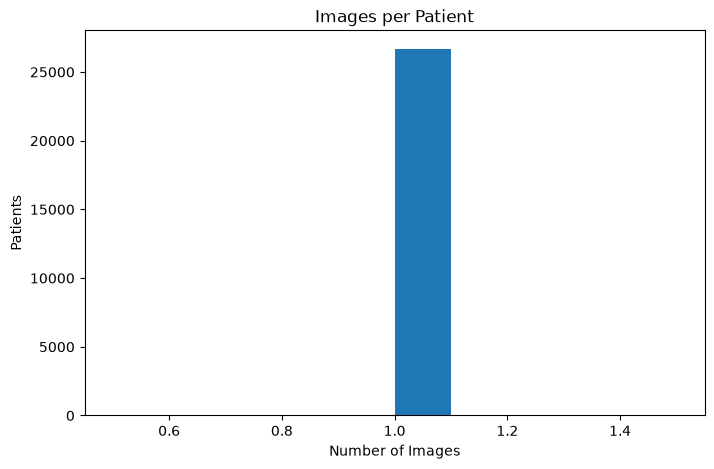

In [6]:
# Images per Patient Histogram 

plt.figure(figsize=(8,5))

plt.hist(
    image_df["image_count"],
    bins=10
)

plt.title("Images per Patient")

plt.xlabel("Number of Images")

plt.ylabel("Patients")

plt.show()

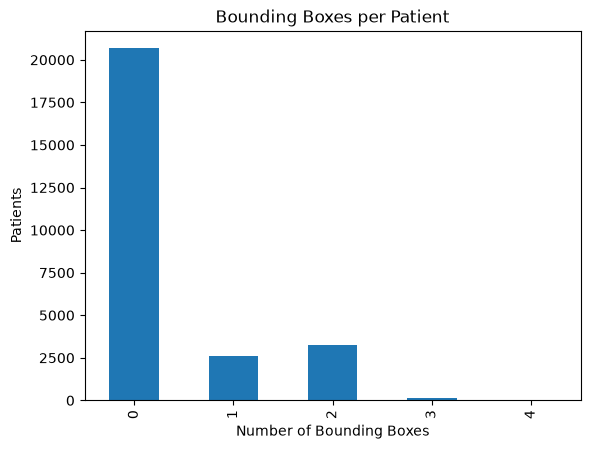

In [7]:
# Bounding Boxes Frequency

bbox_df["num_boxes"].value_counts().sort_index().plot(
    kind="bar"
)

plt.title("Bounding Boxes per Patient")

plt.xlabel("Number of Bounding Boxes")

plt.ylabel("Patients")

plt.show()

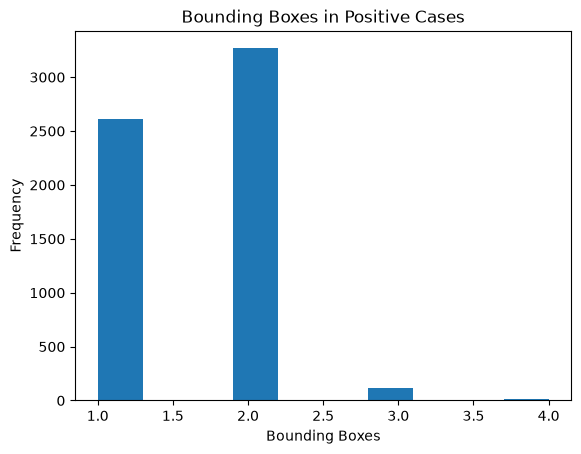

In [8]:
# Positive Patients Only 

positive = bbox_df[
    bbox_df["target"] == 1
]

positive["num_boxes"].plot(
    kind="hist",
    bins=10
)

plt.title("Bounding Boxes in Positive Cases")

plt.xlabel("Bounding Boxes")

plt.show()

In [9]:
# Top Patients with Most Bounding Boxes

bbox_df.sort_values(
    "num_boxes",
    ascending=False
).head(10)

,patient_id,target,num_boxes
25847,0e03c2d7-9cea-4dc7-8e91-794a8b3ff58d,1,4
12629,8dc8e54b-5b05-4dac-80b9-fa48878621e2,1,4
10816,7d674c82-5501-4730-92c5-d241fd6911e7,1,4
947,0d5bc737-03de-4bb8-98a1-45b7180c3e0f,1,4
26114,1c44e0a4-4612-438f-9a83-8d5bf919cb67,1,4
10078,76f71a93-8105-4c79-a010-0cfa86f0061a,1,4
679,0ab261f9-4eb5-42ab-a9a5-e918904d6356,1,4
1974,31764d54-ea3b-434f-bae2-8c579ed13799,1,4
2342,349f10b4-dc3e-4f3f-b2e4-a5b81448ce87,1,4
2063,3239951b-6211-4290-b237-3d9ad17176db,1,4
